# Дополнительные эксперименты

Все данные синтетические. В ноутбуке сравниваются этапы стабилизации, измеряется время QR и проверяются эмбеддинги, обработанные блоками на диске.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "stabilization").is_dir():
    root = root.parent
if not (root / "stabilization").is_dir():
    raise RuntimeError("Откройте ноутбук из папки проекта или из notebooks.")

def read_report(name):
    return json.loads((root / "results" / f"{name}.json").read_text(encoding="utf-8"))

## Вклад SVD и Прокруста

Координаты объектов и пользователей масштабируются взаимно обратным образом. Затем обе матрицы поворачиваются на 75°. Модель сохраняет исходные оценки, а координаты эмбеддингов меняются. Половина объектов участвует в подборе преобразований, вторая половина выделена для оценки.

Исходный вариант и Прокруст сравниваются с исходной версией 0. SVD и полный метод сравниваются с версией 0 в координатах SVD.

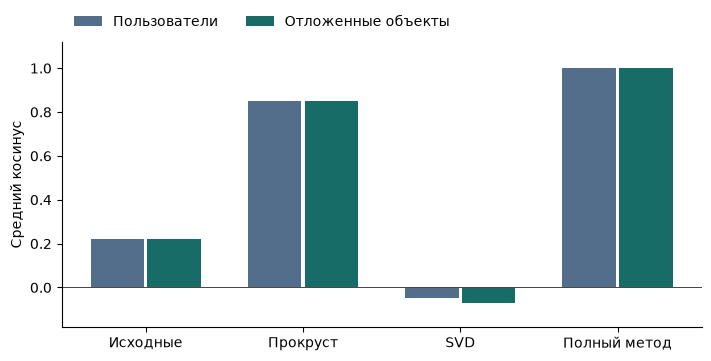

Исходные       | Ошибка при смешении версий: 1.519e+00
Прокруст       | Ошибка при смешении версий: 8.290e-01
SVD            | Ошибка при смешении версий: 1.423e+00
Полный метод   | Ошибка при смешении версий: 1.843e-15


In [2]:
ablation = read_report("ablation")
variants = ablation["variants"]
names = ["Исходные", "Прокруст", "SVD", "Полный метод"]
x = np.arange(len(variants))
users = [row["users_cosine"] for row in variants.values()]
items = [row["held_out_items_cosine"] for row in variants.values()]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.bar(x - 0.18, users, 0.34, color="#526e8b", label="Пользователи")
ax.bar(x + 0.18, items, 0.34, color="#176c67", label="Отложенные объекты")
ax.set(xticks=x, xticklabels=names, ylabel="Средний косинус", ylim=(-0.18, 1.12))
ax.axhline(0, color="#444444", linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncols=2)
plt.show()

for name, row in zip(names, variants.values(), strict=True):
    error = row["mixed_version_score_error"]["relative_l2"]
    print(f"{name:14s} | Ошибка при смешении версий: {error:.3e}")

## QR и TSQR при одинаковом числе CPU-потоков

На каждый запуск выделено четыре потока. Для каждой конфигурации показаны медиана и интервал от 25-го до 75-го процентиля по семи повторам. Полное время команды включает запуск процессов, подготовку данных, прогрев, повторы и проверку. Время QR измеряется отдельно.

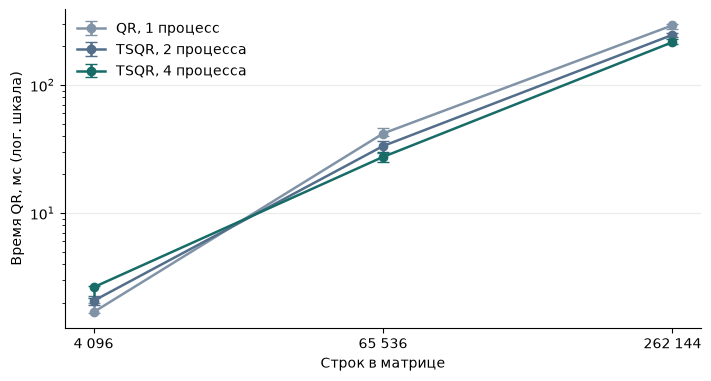

qr   × 1 | Полная команда: 6.55 с | Пик на процесс: 748 МиБ
tsqr × 2 | Полная команда: 10.74 с | Пик на процесс: 638 МиБ
tsqr × 4 | Полная команда: 11.31 с | Пик на процесс: 573 МиБ


In [3]:
benchmark = read_report("qr-benchmark")
measurements = benchmark["measurements"]
sizes = sorted({row["rows"] for row in measurements})
positions = np.arange(len(sizes))
fig, ax = plt.subplots(figsize=(7, 3.7), layout="constrained")
for algorithm, processes, label, color in [
    ("qr", 1, "QR, 1 процесс", "#8193a7"),
    ("tsqr", 2, "TSQR, 2 процесса", "#526e8b"),
    ("tsqr", 4, "TSQR, 4 процесса", "#176c67"),
]:
    series = [
        row["qr_seconds"] for row in measurements
        if row["algorithm"] == algorithm and row["processes"] == processes
    ]
    median = 1000 * np.array([row["median"] for row in series])
    q1 = 1000 * np.array([row["q1"] for row in series])
    q3 = 1000 * np.array([row["q3"] for row in series])
    ax.errorbar(positions, median, yerr=[median - q1, q3 - median],
                marker="o", capsize=4, linewidth=1.8, color=color, label=label)
labels = [f"{size:,}".replace(",", " ") for size in sizes]
ax.set(xticks=positions, xticklabels=labels, xlabel="Строк в матрице",
       ylabel="Время QR, мс (лог. шкала)", yscale="log")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.show()

for row in measurements:
    if row["rows"] == sizes[-1]:
        rss = row["peak_rss_bytes_per_rank_max"] / 2**20
        print(f"{row['algorithm']:4s} × {row['processes']} | Полная команда: {row['command_wall_seconds']:.2f} с | Пик на процесс: {rss:.0f} МиБ")

## Обработка эмбеддингов с диска

Для демонстрации использовались блоки до 127 строк. Эталон рассчитан на двух процессах, новая версия выровнена на четырёх. Команды для создания файлов и повторного запуска есть в [README](../README.md#обработка-файлов-блоками).

In [4]:
stream = read_report("streaming")
print(f"Пользователей: {stream['users']} | Объектов: {stream['items']} | Общих объектов: {stream['anchor_items']}")
print(f"Размер рабочего блока: {stream['block_rows']} строк | Процессы при выравнивании: {stream['processes']}")
print(f"Ошибка оценок на {stream['sampled_pairs']} парах: {stream['relative_score_error']:.2e}")
print(f"Средний косинус пользователей и объектов: {stream['users_cosine']:.6f}, {stream['items_cosine']:.6f}")

Пользователей: 8192 | Объектов: 6144 | Общих объектов: 6144
Размер рабочего блока: 127 строк | Процессы при выравнивании: 4
Ошибка оценок на 2048 парах: 2.08e-15
Средний косинус пользователей и объектов: 1.000000, 1.000000


### Проверка своего файлового запуска

Установите `check_local_run = True` и выполните ячейку. При первом запуске она сгенерирует синтетические файлы, построит эталон и выровняет новую версию. Если в `runs/` уже есть файлы от этих шагов, ячейка использует их повторно. Затем она сверит ID и посчитает метрики на выборке.

In [7]:
def prepare_streaming():
    import subprocess
    import sys

    runs = root / "runs"
    source = runs / "stream-input"
    reference = runs / "stream-reference"
    aligned = runs / "stream-aligned"
    arrays = ("users.npy", "items.npy", "user_ids.npy", "item_ids.npy")
    stages = [
        (
            "Генерация синтетических файлов",
            source,
            tuple(f"{version}/{file}" for version in ("version0", "version1") for file in arrays),
            [
                "-m", "stabilization.streaming", "generate",
                "--users", "8192", "--items", "6144", "--dim", "32",
            ],
        ),
        (
            "Расчёт эталона на двух процессах",
            reference,
            (*arrays, "transforms.pt", "metrics.json"),
            [
                "-m", "stabilization.launch", "--processes", "2", "--module",
                "stabilization.streaming", "reference", "--input", str(source / "version0"),
            ],
        ),
        (
            "Выравнивание на четырёх процессах",
            aligned,
            (*arrays, "transforms.pt", "metrics.json"),
            [
                "-m", "stabilization.launch", "--processes", "4", "--module",
                "stabilization.streaming", "align", "--input", str(source / "version1"),
                "--reference", str(source / "version0"),
                "--checkpoint", str(reference / "transforms.pt"),
            ],
        ),
    ]
    for label, destination, expected_files, command in stages:
        if destination.exists():
            missing = [file for file in expected_files if not (destination / file).is_file()]
            if missing:
                missing_names = ", ".join(missing)
                raise RuntimeError(
                    f"Папка {destination} содержит неполный результат. "
                    f"Не найдены файлы {missing_names}. "
                    "Переименуйте эту папку и повторите проверку."
                )
            continue

        print(label, flush=True)
        result = subprocess.run(
            [sys.executable, *command, "--block-rows", "127", "--output", str(destination)],
            cwd=root, capture_output=True, encoding="utf-8", errors="replace", timeout=180,
        )
        if result.returncode:
            details = result.stderr.strip() or result.stdout.strip()
            raise RuntimeError(f"{label}. Код завершения {result.returncode}.\n{details}")


def check_streaming():
    def load(folder, name):
        return np.load(root / "runs" / folder / f"{name}.npy", mmap_mode="r", allow_pickle=False)

    raw_users = load("stream-input/version1", "users")
    raw_items = load("stream-input/version1", "items")
    users = load("stream-aligned", "users")
    items = load("stream-aligned", "items")
    for entity in ("user_ids", "item_ids"):
        np.testing.assert_array_equal(
            load("stream-input/version1", entity), load("stream-aligned", entity)
        )
    rng = np.random.default_rng(42)
    user_indices = rng.integers(len(users), size=2048)
    item_indices = rng.integers(len(items), size=2048)
    before = (raw_users[user_indices] * raw_items[item_indices]).sum(axis=1)
    after = (users[user_indices] * items[item_indices]).sum(axis=1)

    def matching_cosine(current, reference, indices):
        left, right = current[indices], reference[indices]
        norms = np.linalg.norm(left, axis=1) * np.linalg.norm(right, axis=1)
        return float(np.clip((left * right).sum(axis=1) / norms, -1, 1).mean())

    report = json.loads((root / "runs" / "stream-aligned" / "metrics.json").read_text())
    report["sampled_pairs"] = len(before)
    report["relative_score_error"] = float(np.linalg.norm(after - before) / np.linalg.norm(before))
    report["users_cosine"] = matching_cosine(users, load("stream-reference", "users"), user_indices)
    report["items_cosine"] = matching_cosine(items, load("stream-reference", "items"), item_indices)
    return report


check_local_run = True
if check_local_run:
    prepare_streaming()
    print(json.dumps(check_streaming(), indent=2))

{
  "mode": "align",
  "users": 8192,
  "items": 6144,
  "dim": 32,
  "dtype": "float64",
  "block_rows": 127,
  "processes": 4,
  "effective_rank": 32,
  "anchor_items": 6144,
  "sampled_pairs": 2048,
  "relative_score_error": 2.0797213963430656e-15,
  "users_cosine": 1.0,
  "items_cosine": 1.0
}
